# 08 · Shocks and conservation laws

Nonlinear hyperbolic equations - Burgers, shallow water, gas dynamics - steepen smooth waves into shocks, after
which the PDE holds only in its integral (conservation) form and the solution must be selected by an entropy
condition. The method of lines handles them with finite-volume right-hand sides: fluxes through cell faces from
an approximate Riemann solver, reconstruction with limiters, and any time integrator. This notebook follows
Burgers' equation through breaking, checks shock speeds and rarefactions against the exact Riemann solutions,
and solves Stoker's dam break for the shallow-water system.

**What you will learn**
- write finite-volume right-hand sides for scalar and system conservation laws
- verify shock speeds by Rankine-Hugoniot and entropy-satisfying rarefactions
- check conservation to rounding
- solve a hyperbolic system against an exact Riemann solution

**Before you start:** notebook 07  ·  **Time:** about 75 min

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engmolines import problems as pr, integrators as ti, analysis
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Burgers' equation: steepening and breaking

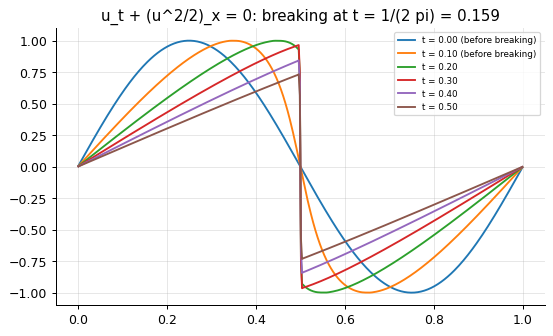

before breaking, vs the characteristic solution: error 5.9e-04; after breaking the integral of u is conserved to -2.8e-17


In [2]:
p = pr.burgers_sine()
s = p.solve("dopri", rtol=1e-8, atol=1e-10, t_end=0.5, n_out=5)
for t, y in zip(s.t, s.y):
    plt.plot(p.x, y, label=f"t = {t:.2f}" + (" (before breaking)" if t < p.params["t_break"] else ""))
plt.legend(fontsize=7); plt.title("u_t + (u^2/2)_x = 0: breaking at t = 1/(2 pi) = 0.159"); plt.show()
s_pre = p.solve("dopri", rtol=1e-8, atol=1e-10, t_end=0.12)
print(f"before breaking, vs the characteristic solution: error {p.error(s_pre):.1e}; after breaking the integral of u is conserved to {p.grid.integrate(s.y[-1]) - p.grid.integrate(p.y0):+.1e}")

Each value of u travels at speed u, so the crests overtake the troughs and the profile steepens until the
slope becomes infinite at t = 1/(2π); after that a shock forms and moves at the Rankine-Hugoniot speed. Before
breaking the finite-volume solution matches the exact characteristic solution to 10⁻³; after it the
conservation form keeps the integral of u exact.

## Riemann problems: shock and rarefaction

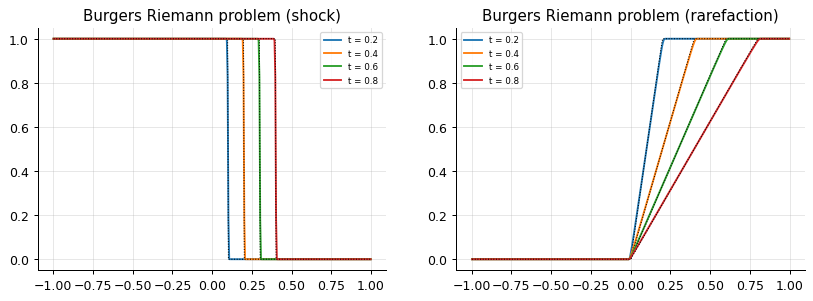

shock at 0.4025 vs (uL + uR)/2 * t = 0.4000; overshoot 0.0e+00


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (uL, uR) in zip(axes, ((1.0, 0.0), (0.0, 1.0))):
    p = pr.burgers_riemann(uL=uL, uR=uR)
    s = p.solve("dopri", rtol=1e-7, atol=1e-9, n_out=4)
    for t, y in zip(s.t[1:], s.y[1:]):
        ax.plot(p.x, y, label=f"t = {t:.1f}"); ax.plot(p.x, p.exact(p.x, t), "k:", lw=0.8)
    ax.set_title(p.name); ax.legend(fontsize=7)
plt.show()
p = pr.burgers_riemann(uL=1.0, uR=0.0); s = p.solve("dopri", rtol=1e-7, atol=1e-9)
print(f"shock at {p.x[np.argmin(np.abs(s.y[-1] - 0.5))]:.4f} vs (uL + uR)/2 * t = {0.5 * 0.8:.4f}; overshoot {s.y[-1].max() - 1:.1e}")

A shock (uL > uR) travels at the Rankine-Hugoniot speed (uL + uR)/2, here within a cell width and without
overshoot; a rarefaction (uL < uR) fans out as u = x/t. The non-entropy "expansion shock" would also satisfy
the conservation law, and a careless scheme produces it; the Rusanov flux's numerical dissipation selects
the physical fan.

## Inside the finite-volume right-hand side

In [4]:
from engmolines import operators as op, grids
g = grids.cell_centred(-1, 1, 10)
u = np.where(g.x < 0, 1.0, 0.0)
rate = op.conservation_law(u, g, lambda w: 0.5 * w * w, lambda w: np.abs(w), "transmissive", "transmissive")
print("state     :", u)
print("rate      :", np.round(rate, 3), "  <- only the cell behind the jump changes: the flux difference (F_L - F_R)/dx = (0.5 - 0)/0.2")
print("sum of rates * dx:", f"{np.sum(rate) * g.dx:.2f}", "= flux in through the left boundary F(1) = 0.5 minus flux out F(0) = 0: the total changes only by what crosses the boundaries")

state     : [1. 1. 1. 1. 1. 0. 0. 0. 0. 0.]
rate      : [-0.   -0.   -0.   -0.   -1.25  3.75 -0.   -0.   -0.   -0.  ]   <- only the cell behind the jump changes: the flux difference (F_L - F_R)/dx = (0.5 - 0)/0.2
sum of rates * dx: 0.50 = flux in through the left boundary F(1) = 0.5 minus flux out F(0) = 0: the total changes only by what crosses the boundaries


The rate of each cell is the difference of the fluxes through its two faces divided by its width; each face
flux is computed once from the states on either side, so whatever leaves one cell enters the next and the
total changes only by the fluxes through the domain's boundaries (exactly zero on a periodic grid). The library's Rusanov flux F* = (F(L) + F(R))/2 − s(R − L)/2 uses the largest
local wave speed s as dissipation; MUSCL reconstruction with a limiter raises the order to two away from jumps.

## The shallow-water dam break

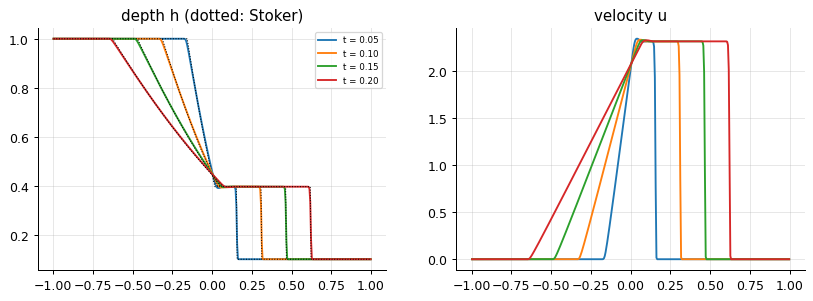

plateau depth 0.3962 (Stoker 0.3962); shock speed 3.105; rarefaction head at -sqrt(g hL) = -3.132
mass conserved to +0.0e+00


In [5]:
p = pr.shallow_water_dam_break(hL=1.0, hR=0.1)
s = p.solve("dopri", rtol=1e-7, atol=1e-9, n_out=4)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for t, y in zip(s.t[1:], s.y[1:]):
    h, q = y[:400], y[400:]
    axes[0].plot(p.x, h, label=f"t = {t:.2f}"); axes[0].plot(p.x, p.exact(p.x, t)[0], "k:", lw=0.8)
    axes[1].plot(p.x, q / h)
axes[0].set_title("depth h (dotted: Stoker)"); axes[0].legend(fontsize=7); axes[1].set_title("velocity u"); plt.show()
h = s.y[-1][:400]
print(f"plateau depth {np.median(h[(p.x > 0.05) & (p.x < 0.3)]):.4f} (Stoker {p.params['h_m']:.4f}); shock speed {p.params['shock_speed']:.3f}; rarefaction head at -sqrt(g hL) = {-np.sqrt(9.81):.3f}")
print(f"mass conserved to {p.grid.integrate(h) - p.grid.integrate(p.y0[:400]):+.1e}")

The shallow-water equations are a 2 × 2 system; the same finite-volume operator handles it with vector states,
component-wise reconstruction and the wave speed |u| + √(gh). Removing the dam sends a rarefaction into the
deep water and a shock (a bore) into the shallow, with a plateau between them whose depth Stoker's exact
solution gives; the computed plateau agrees to 10⁻³ and the fronts sit within a cell of their exact positions.

## Inside the algorithm: the Rusanov flux

In [6]:
uL, uR = 1.0, 0.0
F = lambda u: 0.5 * u * u  # noqa: E731
s_max = max(abs(uL), abs(uR))
print("Rusanov flux at the jump:", 0.5 * (F(uL) + F(uR)) - 0.5 * s_max * (uR - uL), "= average flux + dissipation s (uL - uR)/2")
print("the exact Godunov flux for this shock is F(uL) =", F(uL), "(the shock moves right, so the left state feeds the face)")

Rusanov flux at the jump: 0.75 = average flux + dissipation s (uL - uR)/2
the exact Godunov flux for this shock is F(uL) = 0.5 (the shock moves right, so the left state feeds the face)


## Exercises
1. Start Burgers' equation from a smooth bump u0 = exp(-x^2) and measure the shock's position and the integral of u against the exact Rankine-Hugoniot prediction from the pre-shock profile (the equal-area rule).
2. Dam break onto dry ground (hR = 0): what breaks in the shallow-water right-hand side, and how do real codes handle it? Try hR = 1e-3 and compare the front speed with 2 sqrt(g hL).
3. **Implement it yourself:** write the Godunov flux for Burgers' equation (the exact Riemann solver for a convex flux) and compare its shock resolution with the Rusanov flux.